# 07 · Negative-Review Risk Model: the Day-0 Alert

**Business problem** (from notebook 04): ratings collapse 1–3 days after a missed promise, and late orders are ~6.7× as likely
to get 1–2★. If risky orders are flagged **when the seller hands the parcel to the carrier**, there is still time to act:
a proactive tracking message, an apology voucher, or an expedited carrier.

**Approach**
- Target: `review_score ≤ 2`. Features are only what's known at carrier handoff: purchase-time features plus
  how fast the seller dispatched, whether it missed its shipping deadline, and how many days remain before the promise.
- Three models on the same time split: a logistic-regression baseline, LightGBM with purchase-time features only,
  and LightGBM with dispatch-time features.
- Judged on **ranking** (PR-AUC, lift in the top 10%), because operations can only contact a fraction of orders.

Code: [`src/ecom/models/review_risk.py`](../src/ecom/models/review_risk.py)

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ecom import viz
from ecom.features import build_features

warnings.filterwarnings("ignore", category=UserWarning)
viz.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
features = build_features()  # leakage-safe, see src/ecom/features.py

In [ ]:
from sklearn.metrics import precision_recall_curve

from ecom.models import review_risk

model, metrics, scored = review_risk.train(features)
print(
    f"Test orders: {metrics['rows']['test']:,}  ·  negative-review base rate: {metrics['test_base_rate']:.1%}"
)
pd.DataFrame(metrics["models"]).T

Test orders: 18,520  ·  negative-review base rate: 9.7%


,roc_auc,pr_auc,precision_top10%,recall_top10%,lift_top10%
Logistic regression (dispatch),0.655,0.208,0.250,0.257,2.569
LightGBM (purchase-time),0.624,0.183,0.225,0.231,2.309
LightGBM (dispatch-time),0.661,0.240,0.274,0.281,2.814


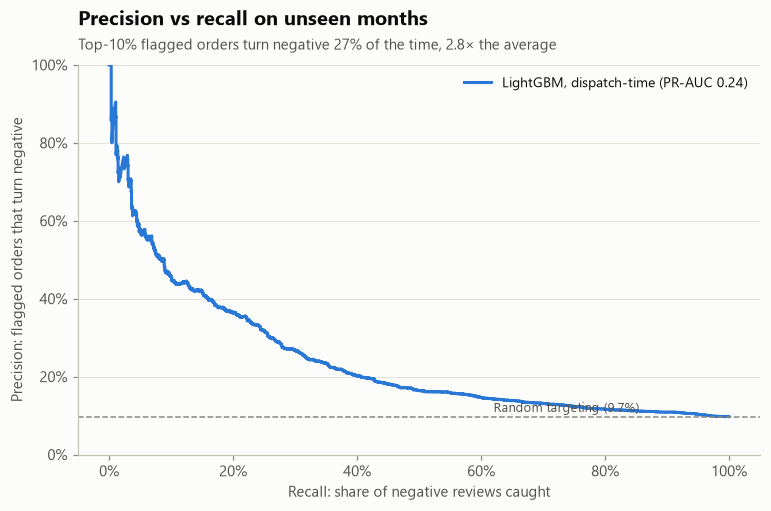

In [ ]:
df = review_risk.modelling_frame(features)
tr, te = df[df["split"] == "train"], df[df["split"] == "test"]

fig, ax = plt.subplots(figsize=(8, 4.6))
prec, rec, _ = precision_recall_curve(scored["target"], scored["risk"])
ax.plot(
    rec * 100,
    prec * 100,
    color=viz.BLUE,
    label=f"LightGBM, dispatch-time (PR-AUC {metrics['models']['LightGBM (dispatch-time)']['pr_auc']:.2f})",
)
ax.axhline(metrics["test_base_rate"] * 100, color=viz.MUTED, linestyle="--", linewidth=1)
ax.text(
    62,
    metrics["test_base_rate"] * 100 + 1.2,
    f"Random targeting ({metrics['test_base_rate']:.1%})",
    fontsize=8.5,
    color=viz.INK_2,
)
ax.xaxis.set_major_formatter(viz.PCT)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Recall: share of negative reviews caught")
ax.set_ylabel("Precision: flagged orders that turn negative")
ax.set_ylim(0, 100)
ax.legend(loc="upper right")
ax.set_title("Precision vs recall on unseen months")
top10 = metrics["models"]["LightGBM (dispatch-time)"]
viz.subtitle(
    ax,
    f"Top-10% flagged orders turn negative {top10['precision_top10%']:.0%} of the time, "
    f"{top10['lift_top10%']:.1f}× the average",
)
viz.save(fig, "review_risk_pr_curve")
plt.show()

## How many bad reviews can operations reach?

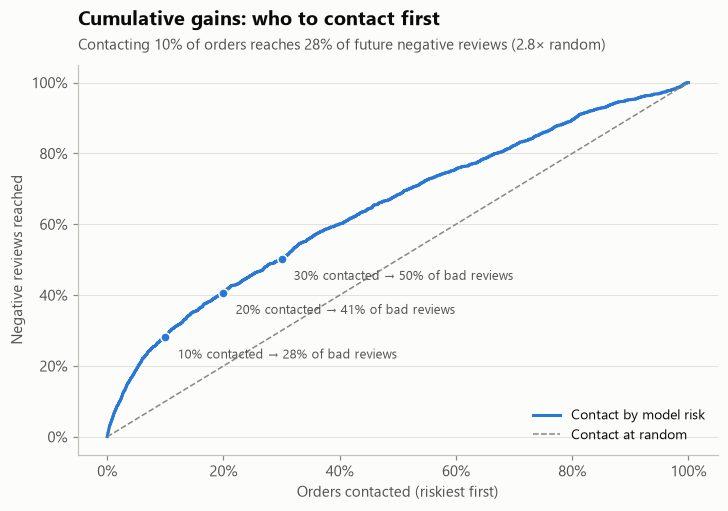

In [ ]:
s = scored.sort_values("risk", ascending=False).reset_index(drop=True)
share_contacted = (np.arange(1, len(s) + 1) / len(s)) * 100
share_caught = s["target"].cumsum() / s["target"].sum() * 100

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(share_contacted, share_caught, color=viz.BLUE, label="Contact by model risk")
ax.plot([0, 100], [0, 100], color=viz.MUTED, linestyle="--", linewidth=1, label="Contact at random")
for pct in (10, 20, 30):
    i = int(len(s) * pct / 100) - 1
    ax.scatter(
        share_contacted[i],
        share_caught.iloc[i],
        color=viz.BLUE,
        s=36,
        zorder=3,
        edgecolor=viz.SURFACE,
    )
    ax.annotate(
        f"{pct}% contacted → {share_caught.iloc[i]:.0f}% of bad reviews",
        (share_contacted[i], share_caught.iloc[i]),
        xytext=(8, -14),
        textcoords="offset points",
        fontsize=8.5,
        color=viz.INK_2,
    )
ax.xaxis.set_major_formatter(viz.PCT)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Orders contacted (riskiest first)")
ax.set_ylabel("Negative reviews reached")
ax.legend(loc="lower right")
ax.set_title("Cumulative gains: who to contact first")
i10 = int(len(s) * 0.1) - 1
viz.subtitle(
    ax,
    f"Contacting 10% of orders reaches {share_caught.iloc[i10]:.0f}% of future negative reviews "
    f"({share_caught.iloc[i10] / 10:.1f}× random)",
)
viz.save(fig, "review_risk_gains")
plt.show()

## Why does the model flag an order? (SHAP)

F:\E-commerce Sales & Customer Insights\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


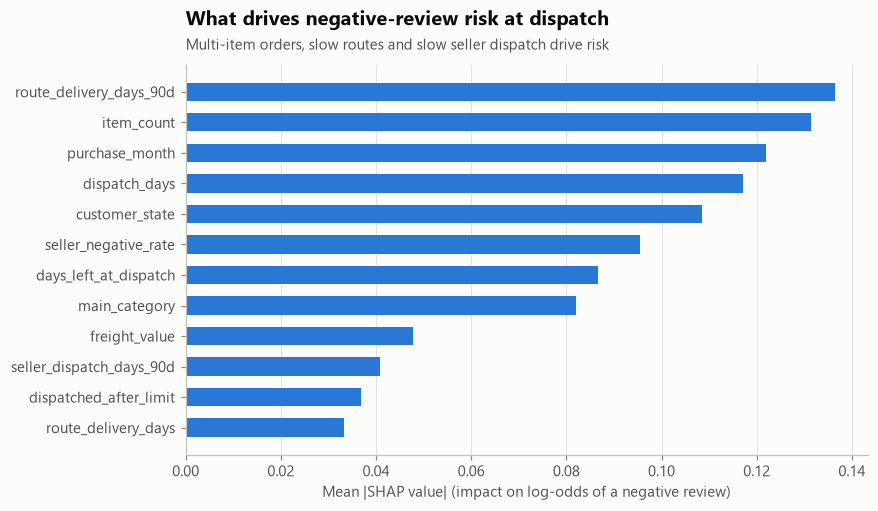

,"corr(value, SHAP): + means higher value = more risk"
route_delivery_days_90d,0.930
item_count,0.850
purchase_month,0.190
dispatch_days,0.960
seller_negative_rate,0.880
days_left_at_dispatch,-0.780
freight_value,0.780
seller_dispatch_days_90d,0.480
dispatched_after_limit,0.970
route_delivery_days,0.880


In [ ]:
import shap

sample = te.sample(3000, random_state=42)
explainer = shap.TreeExplainer(model.model)
sv = explainer.shap_values(sample[model.features])
sv = sv[1] if isinstance(sv, list) else sv
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=model.features).sort_values().tail(12)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(mean_abs.index, mean_abs.values, color=viz.BLUE, height=0.6)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Mean |SHAP value| (impact on log-odds of a negative review)")
ax.set_title("What drives negative-review risk at dispatch")
viz.subtitle(ax, "Multi-item orders, slow routes and slow seller dispatch drive risk")
viz.save(fig, "review_risk_shap")
plt.show()

# Direction of the effect: correlation between a feature's value and its SHAP contribution
numeric = [f for f in mean_abs.index[::-1] if f in sample.select_dtypes("number").columns]
direction = {
    f: np.corrcoef(sample[f].fillna(sample[f].median()), sv[:, model.features.index(f)])[0, 1]
    for f in numeric
}
pd.Series(direction, name="corr(value, SHAP): + means higher value = more risk").round(2).to_frame()

The explanations are plausible business mechanisms, which is a good sanity check that the model isn't keying on noise:

- **Multi-item orders → more risk.** One of the two strongest drivers. Items from one order often ship separately, so the customer
  sees a partial delivery or a missing item, a frustration the delivery date alone doesn't capture.
- **Slow routes and slow dispatch → more risk:** recent route delivery time, days from purchase to handoff, and **missing the
  seller's shipping deadline** all push toward a late arrival (notebook 04's mechanism).
- **Fewer days left before the promise at handoff → more risk:** the parcel is unlikely to make it in time.
- **Sellers with a history of negative reviews** carry their risk forward.
- `purchase_month` ranks high because risk varied over time (the Feb–Mar 2018 spike). It's useful, but worth monitoring for drift.

## Conclusions

1. Dispatch-time information adds real signal: PR-AUC rises from ~0.18 (purchase-time) to **~0.24** (dispatch-time),
   about **2.5× the 9.7% base rate**, and beats the logistic-regression baseline.
2. Operations contacting the riskiest **10%** of orders reach **~28%** of future negative reviews (see the gains chart for 20–30%).
3. **Multi-item orders** are the top risk driver, so a cheap rule ("message every split shipment") is worth testing alongside the model.
4. **Limitation:** reviews also depend on product quality and customer expectations, which this data doesn't capture.
   The model is a *prioritisation* tool, not a per-order oracle.

## How to deploy and measure it

- Score every order at carrier handoff; send the top 10% to a proactive-care flow.
- **A/B test:** randomly hold out half of the flagged orders. The success metric is the negative-review rate of treated vs held-out flagged orders.
  Only the experiment can show whether the intervention *changes* outcomes. The model only says *who* to target.